# Medical appointment data: exploratory data analysis\n\nThis EDA uses the cleaned CSV. It documents quality, distributions, missingness, appointment outcomes, and calendar trends.\n

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 100)
from clinic_ml import load_analysis_data
Path('artifacts').mkdir(exist_ok=True)
df = load_analysis_data(Path('Medical_appointment_data_clean_filled.csv'))
print(f'Shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
display(df.head())


Shape: 109,593 rows x 36 columns


,appointment_time,place,age,patient_needs_companion,average_temp_day,average_rain_day,max_temp_day,max_rain_day,rainy_day_before,storm_day_before,appointment_date_continuous,hipertension,diabetes,alcoholism,handcap,scholarship,sms_received,under_12,over_60,appointment_hour,appointment_month,appointment_week_of_year,is_weekend,appointment_day_index,no_show,gender,specialty,disability,appointment_shift,day_of_week,month_sin,month_cos,day_of_year_sin,day_of_year_cos,companion_child,chronic_count
0,17,Lake Marvinville,9.0,1,23.18,0.12,27.5,1.3,1,1,2020-01-01,0,0,0,0,0,0,1.0,0.0,17,1,1,0,0,yes,f,psychotherapy,intellectual,afternoon,2,0.5,0.866025,0.017202,0.999852,1.0,0
1,7,ITAPEMA,11.0,1,14.31,0.02,16.5,0.6,1,1,2020-01-01,0,0,0,0,0,0,1.0,0.0,7,1,1,0,0,no,m,general,intellectual,morning,2,0.5,0.866025,0.017202,0.999852,1.0,0
2,16,ITAJAÍ,8.0,1,21.61,0.01,29.9,0.2,1,1,2020-01-01,0,0,0,0,0,0,1.0,0.0,16,1,1,0,0,no,m,speech therapy,intellectual,afternoon,2,0.5,0.866025,0.017202,0.999852,1.0,0
3,14,Sarahside,9.0,1,21.39,0.11,24.1,1.4,1,1,2020-01-01,0,0,0,0,0,1,1.0,0.0,14,1,1,0,0,yes,m,speech therapy,intellectual,afternoon,2,0.5,0.866025,0.017202,0.999852,1.0,0
4,8,ITAJAÍ,12.0,0,20.15,0.02,23.1,0.2,1,1,2020-01-01,0,0,0,0,0,0,0.0,0.0,8,1,1,0,0,no,m,physiotherapy,motor,morning,2,0.5,0.866025,0.017202,0.999852,0.0,0


In [2]:
# Replace requested missing values and save the updated data as a new CSV.

df['specialty'] = df['specialty'].fillna('General')
df['disability'] = df['disability'].fillna('No')
Path('artifacts').mkdir(exist_ok=True)
output_path = 'artifacts/notebook_cleaned.csv'
df.to_csv(output_path, index=False)
print(f'Saved updated data to: {output_path}')


Saved updated data to: artifacts/notebook_cleaned.csv


## Missing-value imputation

Missing values are treated before feature engineering. Mean, median, and mode are used according to field type; these transformations remain in memory only.


In [3]:
# Exploratory imputation only; measured zero rainfall is valid, not missing.
# Binary 0/1 fields are not changed.

# Mean imputation for temperature measures.
mean_columns = [column for column in ['avg_temp', 'average_temp_day', 'max_temp', 'max_temp_day'] if column in df.columns]
for column in mean_columns:
    df[column] = df[column].fillna(df[column].mean())

# Impute missing rainfall, preserving observed zeros.
rain_columns = [column for column in ['avg_rain', 'average_rain_day', 'max_rain', 'max_rain_day'] if column in df.columns]
for column in rain_columns:
    df[column] = df[column].fillna(df[column].median())

# Median imputation for age and appointment time.
median_columns = [column for column in ['age', 'appointment_time'] if column in df.columns]
for column in median_columns:
    df[column] = df[column].fillna(df[column].median())

# Standardize age flags after age imputation.
df['under_12'] = (df['age'] < 12).astype('int8')
df['over_60'] = (df['age'] > 60).astype('int8')
df = df.drop(columns=['under_12_years_old', 'over_60_years_old'], errors='ignore')

# Mode imputation for categorical fields.
mode_columns = [column for column in ['gender', 'place', 'appointment_shift', 'rain_intensity', 'heat_intensity'] if column in df.columns]
for column in mode_columns:
    if df[column].isna().any():
        df[column] = df[column].fillna(df[column].mode(dropna=True).iloc[0])

# Save the fully imputed data.
Path('artifacts').mkdir(exist_ok=True)
output_path = 'artifacts/notebook_cleaned.csv'
df.to_csv(output_path, index=False)



## Feature engineering

Derived patient, time, and calendar features are created below for exploration or later modeling.


In [4]:
# Make this cell safe to run independently.
from pathlib import Path
import pandas as pd
if 'df' not in globals():
    from clinic_ml import load_analysis_data
    df = load_analysis_data(Path('Medical_appointment_data_clean_filled.csv'))

# Patient features: recompute age flags from the cleaned age value.
df['under_12'] = (df['age'] < 12).astype('Int64').where(df['age'].notna(), pd.NA)
df['over_60'] = (df['age'] > 60).astype('Int64').where(df['age'].notna(), pd.NA)
df['age_group'] = pd.cut(df['age'], bins=[-1, 11, 17, 39, 59, float('inf')], labels=['Under 12', '12-17', '18-39', '40-59', '60+'])

# Appointment-time features.
df['appointment_hour'] = pd.to_numeric(df['appointment_time'], errors='coerce')
df['appointment_time_band'] = pd.cut(df['appointment_hour'], bins=[-1, 7, 11, 15, 23], labels=['Early morning', 'Morning', 'Afternoon', 'Evening'])

# Calendar features from the continuous appointment date.
df['appointment_date_continuous'] = pd.to_datetime(df['appointment_date_continuous'], errors='coerce')
df['appointment_day_of_week'] = df['appointment_date_continuous'].dt.day_name()
df['appointment_month'] = df['appointment_date_continuous'].dt.month
df['appointment_week_of_year'] = df['appointment_date_continuous'].dt.isocalendar().week.astype('Int64')
df['is_weekend'] = df['appointment_date_continuous'].dt.dayofweek.isin([5, 6]).astype('Int64')
df['appointment_day_index'] = (df['appointment_date_continuous'] - df['appointment_date_continuous'].min()).dt.days

engineered_features = ['under_12', 'over_60', 'age_group', 'appointment_hour', 'appointment_time_band', 'appointment_day_of_week', 'appointment_month', 'appointment_week_of_year', 'is_weekend', 'appointment_day_index']
display(df[engineered_features].head())
print('Engineered features:', ', '.join(engineered_features))

# Persist the cleaned dataset together with the new derived features.
Path('artifacts').mkdir(exist_ok=True)
output_path = 'artifacts/notebook_cleaned.csv'
df.to_csv(output_path, index=False)
print(f'Saved dataset with engineered features to: {output_path}')


,under_12,over_60,age_group,appointment_hour,appointment_time_band,appointment_day_of_week,appointment_month,appointment_week_of_year,is_weekend,appointment_day_index
0,1,0,Under 12,17,Evening,Wednesday,1,1,0,0
1,1,0,Under 12,7,Early morning,Wednesday,1,1,0,0
2,1,0,Under 12,16,Evening,Wednesday,1,1,0,0
3,1,0,Under 12,14,Afternoon,Wednesday,1,1,0,0
4,0,0,12-17,8,Morning,Wednesday,1,1,0,0


Engineered features: under_12, over_60, age_group, appointment_hour, appointment_time_band, appointment_day_of_week, appointment_month, appointment_week_of_year, is_weekend, appointment_day_index


Saved dataset with engineered features to: artifacts/notebook_cleaned.csv


## One-hot encoding

Categorical predictors are converted to binary indicator columns. The target is not encoded.


In [5]:
# One-hot encode categorical predictors and save the model-ready dataset.
# Place is deliberately excluded: it has thousands of distinct location values, which makes one-hot encoding impractically wide.
categorical_features = ['gender', 'specialty', 'disability', 'appointment_shift', 'age_group', 'appointment_time_band', 'appointment_day_of_week', 'rain_intensity', 'heat_intensity']
categorical_features = [column for column in categorical_features if column in df.columns]
from time import perf_counter

start = perf_counter()
X = df.drop(columns=['no_show'])
encoded_data = pd.get_dummies(X, columns=categorical_features, dummy_na=True, dtype='int8')
encoded_data['no_show'] = df['no_show'].map({'no': 0, 'yes': 1})

# Keep the cleaned, feature-engineered CSV intact; the encoded matrix is a separate model artifact.
Path('artifacts').mkdir(exist_ok=True)
output_path = 'artifacts/notebook_encoded.csv'
encoded_data.to_csv(output_path, index=False)

print('Categorical features encoded:', categorical_features)
print(f'Encoded dataset: {encoded_data.shape[0]:,} rows x {encoded_data.shape[1]:,} columns')
print(f'Saved one-hot encoded data to: {output_path}')
print(f'Completed in {perf_counter() - start:.2f} seconds')
display(encoded_data.head())


Categorical features encoded: ['gender', 'specialty', 'disability', 'appointment_shift', 'age_group', 'appointment_time_band', 'appointment_day_of_week']
Encoded dataset: 109,593 rows x 73 columns
Saved one-hot encoded data to: artifacts/notebook_encoded.csv
Completed in 10.26 seconds


,appointment_time,place,age,patient_needs_companion,average_temp_day,average_rain_day,max_temp_day,max_rain_day,rainy_day_before,storm_day_before,appointment_date_continuous,hipertension,diabetes,alcoholism,handcap,scholarship,sms_received,under_12,over_60,appointment_hour,appointment_month,appointment_week_of_year,is_weekend,appointment_day_index,day_of_week,month_sin,month_cos,day_of_year_sin,day_of_year_cos,companion_child,chronic_count,gender_f,gender_i,gender_m,gender_<NA>,specialty_assist,specialty_enf,specialty_general,specialty_occupational therapy,specialty_pedagogo,specialty_physiotherapy,specialty_psychotherapy,specialty_sem especialidade,specialty_speech therapy,specialty_<NA>,disability_Unknown,disability_intellectual,disability_motor,disability_no,disability_<NA>,appointment_shift_afternoon,appointment_shift_morning,appointment_shift_<NA>,age_group_Under 12,age_group_12-17,age_group_18-39,age_group_40-59,age_group_60+,age_group_nan,appointment_time_band_Early morning,appointment_time_band_Morning,appointment_time_band_Afternoon,appointment_time_band_Evening,appointment_time_band_nan,appointment_day_of_week_Friday,appointment_day_of_week_Monday,appointment_day_of_week_Saturday,appointment_day_of_week_Sunday,appointment_day_of_week_Thursday,appointment_day_of_week_Tuesday,appointment_day_of_week_Wednesday,appointment_day_of_week_nan,no_show
0,17,Lake Marvinville,9.0,1,23.18,0.12,27.5,1.3,1,1,2020-01-01,0,0,0,0,0,0,1,0,17,1,1,0,0,2,0.5,0.866025,0.017202,0.999852,1.0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1
1,7,ITAPEMA,11.0,1,14.31,0.02,16.5,0.6,1,1,2020-01-01,0,0,0,0,0,0,1,0,7,1,1,0,0,2,0.5,0.866025,0.017202,0.999852,1.0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0
2,16,ITAJAÍ,8.0,1,21.61,0.01,29.9,0.2,1,1,2020-01-01,0,0,0,0,0,0,1,0,16,1,1,0,0,2,0.5,0.866025,0.017202,0.999852,1.0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0
3,14,Sarahside,9.0,1,21.39,0.11,24.1,1.4,1,1,2020-01-01,0,0,0,0,0,1,1,0,14,1,1,0,0,2,0.5,0.866025,0.017202,0.999852,1.0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1
4,8,ITAJAÍ,12.0,0,20.15,0.02,23.1,0.2,1,1,2020-01-01,0,0,0,0,0,0,0,0,8,1,1,0,0,2,0.5,0.866025,0.017202,0.999852,0.0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0


In [6]:
quality = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_pct': (df.isna().mean()*100).round(2),
    'unique_values': df.nunique(dropna=True)
}).sort_values('missing_pct', ascending=False)
display(df.dtypes.to_frame('dtype').T)
display(quality)
print('Exact duplicate rows:', df.duplicated().sum())
dates = df['appointment_date_continuous'].dropna()
print('Calendar range:', dates.min().date(), 'to', dates.max().date())
print('Missing calendar days:', len(pd.date_range(dates.min(), dates.max()).difference(dates.unique())))


,appointment_time,place,age,patient_needs_companion,average_temp_day,average_rain_day,max_temp_day,max_rain_day,rainy_day_before,storm_day_before,appointment_date_continuous,hipertension,diabetes,alcoholism,handcap,scholarship,sms_received,under_12,over_60,appointment_hour,appointment_month,appointment_week_of_year,is_weekend,appointment_day_index,no_show,gender,specialty,disability,appointment_shift,day_of_week,month_sin,month_cos,day_of_year_sin,day_of_year_cos,companion_child,chronic_count,age_group,appointment_time_band,appointment_day_of_week
dtype,int64,string,float64,int64,float64,float64,float64,float64,int64,int64,datetime64[us],int64,int64,int64,int64,int64,int64,Int64,Int64,int64,int32,Int64,Int64,int64,str,string,string,string,string,int32,float64,float64,float64,float64,float64,int64,category,category,str


,missing_count,missing_pct,unique_values
appointment_time,0,0.0,12
place,0,0.0,26289
age,0,0.0,92
patient_needs_companion,0,0.0,2
average_temp_day,0,0.0,1728
average_rain_day,0,0.0,261
max_temp_day,0,0.0,223
max_rain_day,0,0.0,325
rainy_day_before,0,0.0,2
storm_day_before,0,0.0,2


Exact duplicate rows: 36
Calendar range: 2020-01-01 to 2021-05-12
Missing calendar days: 0


,no_show,appointments,pct
0,no,74761,68.22
1,yes,34832,31.78


C:\Users\ABCD\AppData\Local\Temp\ipykernel_13628\3041057556.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='no_show', order=['no','yes'], ax=axes[0], palette=['#4C78A8','#E45756'])


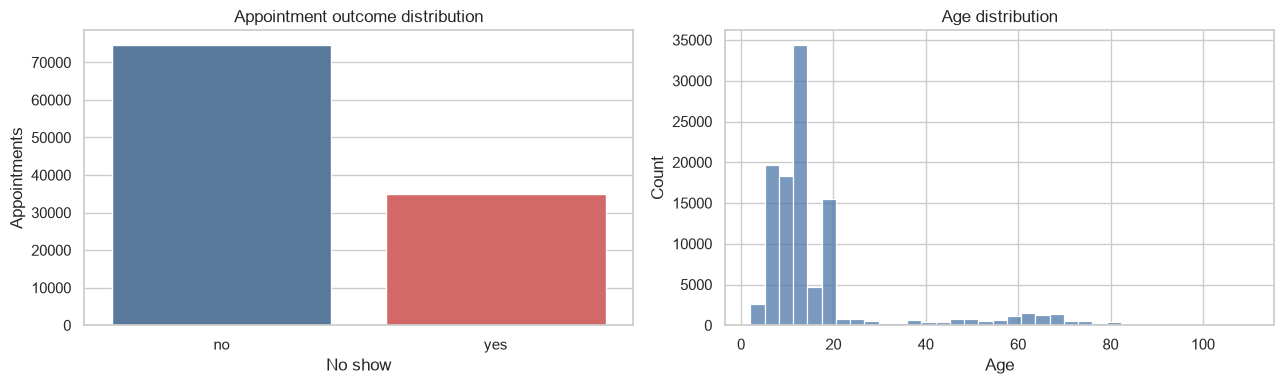

In [7]:
target = df['no_show'].value_counts().rename_axis('no_show').reset_index(name='appointments')
target['pct'] = (100 * target['appointments'] / len(df)).round(2)
display(target)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x='no_show', order=['no','yes'], ax=axes[0], palette=['#4C78A8','#E45756'])
axes[0].set(title='Appointment outcome distribution', xlabel='No show', ylabel='Appointments')
sns.histplot(data=df, x='age', bins=35, ax=axes[1], color='#4C78A8')
axes[1].set(title='Age distribution', xlabel='Age')
plt.tight_layout(); plt.show()


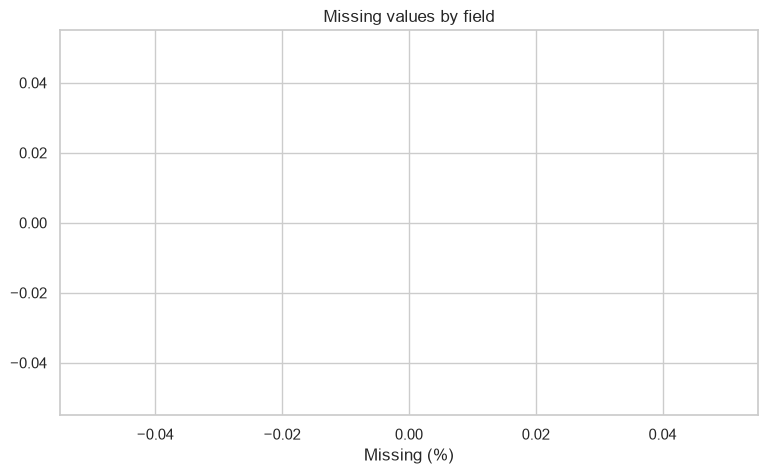

,gender,total,no_show_rate
0,m,82269,31.20
1,f,27077,33.69
2,i,247,17.41


,appointment_shift,total,no_show_rate
0,afternoon,59334,30.71
1,morning,50259,33.05


,specialty,total,no_show_rate
0,psychotherapy,28645,32.34
1,speech therapy,22322,27.93
2,physiotherapy,21004,34.36
3,general,20127,40.63
4,occupational therapy,11319,23.86
5,pedagogo,3536,15.98
6,enf,1681,19.75
7,assist,635,26.93
8,sem especialidade,324,52.78


,disability,total,no_show_rate
0,intellectual,62852,28.99
1,motor,29721,29.08
2,no,16601,46.30
3,Unknown,419,67.78


,place,total,no_show_rate
0,ITAJAÍ,32054,18.19
1,B. CAMBORIU,6018,9.19
2,CAMBORIU,5523,7.44
3,NAVEGANTES,3901,10.51
4,ITAPEMA,2665,9.68
5,BOMBINHAS,1707,11.72
6,PENHA,1039,6.16
7,PORTO BELO,950,11.68
8,BALN. PIÇARRAS,945,6.67
9,ILHOTA,583,13.21


,under_12,total,no_show_rate
0,0,68926,34.02
1,1,40667,28.00


,over_60,total,no_show_rate
0,0,103372,32.35
1,1,6221,22.39


,patient_needs_companion,total,no_show_rate
0,1,56969,28.97
1,0,52624,34.83


In [8]:
missing = quality.query('missing_count > 0').sort_values('missing_pct')
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(missing.index, missing['missing_pct'], color='#F2CF5B')
ax.set(title='Missing values by field', xlabel='Missing (%)', ylabel='')
for i, value in enumerate(missing['missing_pct']):
    ax.text(value + .15, i, f'{value:.1f}%')
plt.show()

def no_show_by(column, top_n=12):
    from clinic_ml import no_show_summary
    return no_show_summary(df, column, top_n)


for field in [
    'gender', 'appointment_shift', 'specialty', 'disability',
    'place', 'under_12', 'over_60', 'patient_needs_companion'
]:
    display(no_show_by(field))


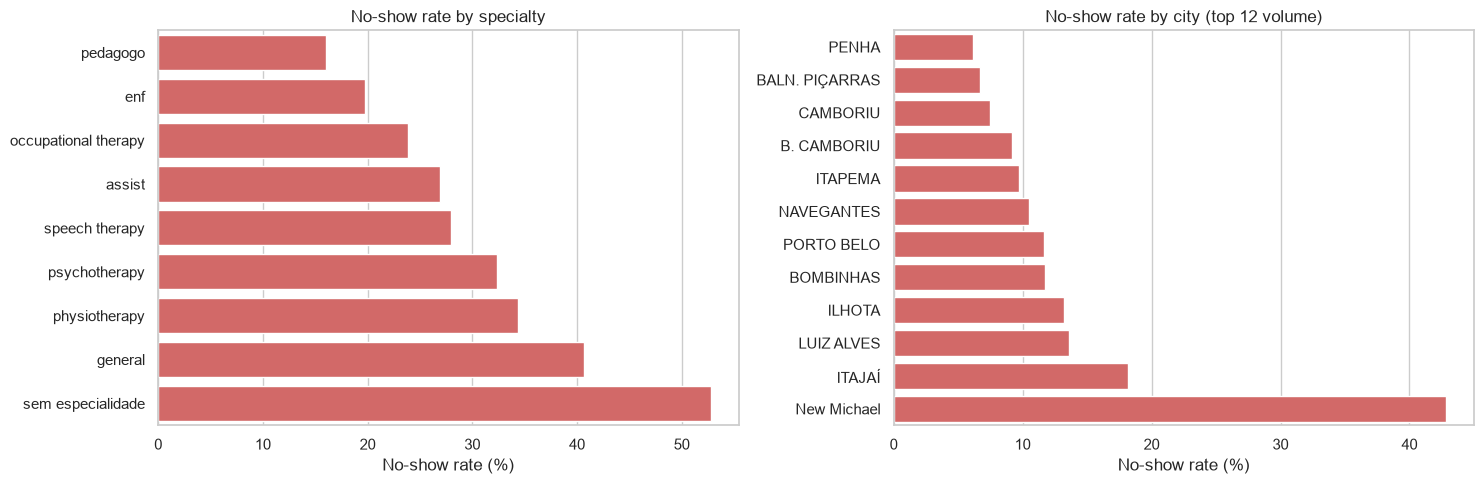

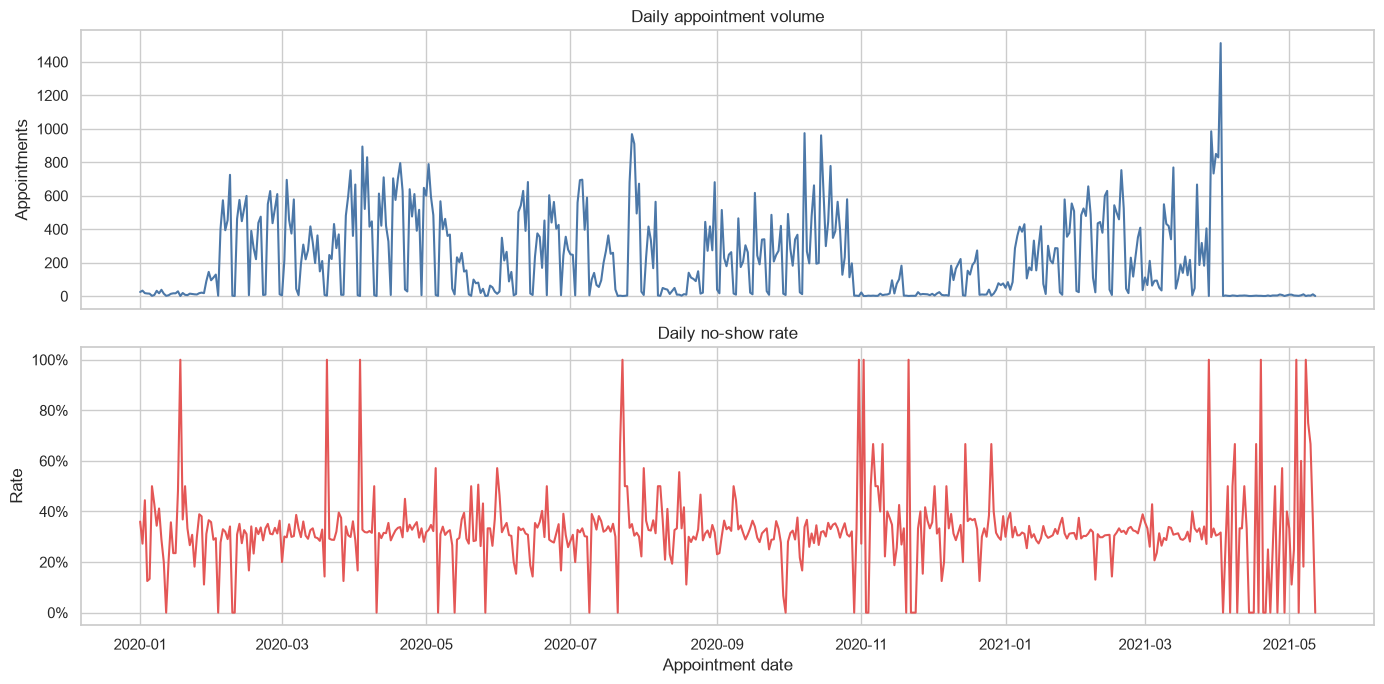

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, field, title in zip(axes, ['specialty','place'], ['No-show rate by specialty', 'No-show rate by city (top 12 volume)']):
    rates = no_show_by(field).sort_values('no_show_rate')
    sns.barplot(data=rates, x='no_show_rate', y=field, ax=ax, color='#E45756')
    ax.set(title=title, xlabel='No-show rate (%)', ylabel='')
plt.tight_layout(); plt.show()

daily = (df.assign(no_show_flag=df['no_show'].eq('yes')).groupby('appointment_date_continuous')
         .agg(appointments=('no_show','size'), no_show_rate=('no_show_flag','mean')).reset_index())
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
sns.lineplot(data=daily, x='appointment_date_continuous', y='appointments', ax=axes[0], color='#4C78A8')
sns.lineplot(data=daily, x='appointment_date_continuous', y='no_show_rate', ax=axes[1], color='#E45756')
axes[0].set(title='Daily appointment volume', xlabel='', ylabel='Appointments')
axes[1].set(title='Daily no-show rate', xlabel='Appointment date', ylabel='Rate')
axes[1].yaxis.set_major_formatter(lambda x, pos: f'{x:.0%}')
plt.tight_layout(); plt.show()


## Outlier detection

Potential outliers are identified with the interquartile range (IQR) rule. This is a diagnostic only and does not remove or modify records.


,feature,lower_bound,upper_bound,outlier_count,outlier_pct
4,average_rain_day,0.03,0.22,37144,33.89
5,max_rain_day,-1.70,3.90,14294,13.04
0,age,-4.50,31.50,11974,10.93
2,average_temp_day,11.43,29.38,920,0.84
3,max_temp_day,13.70,34.50,512,0.47
1,appointment_time,0.00,24.00,0,0.00


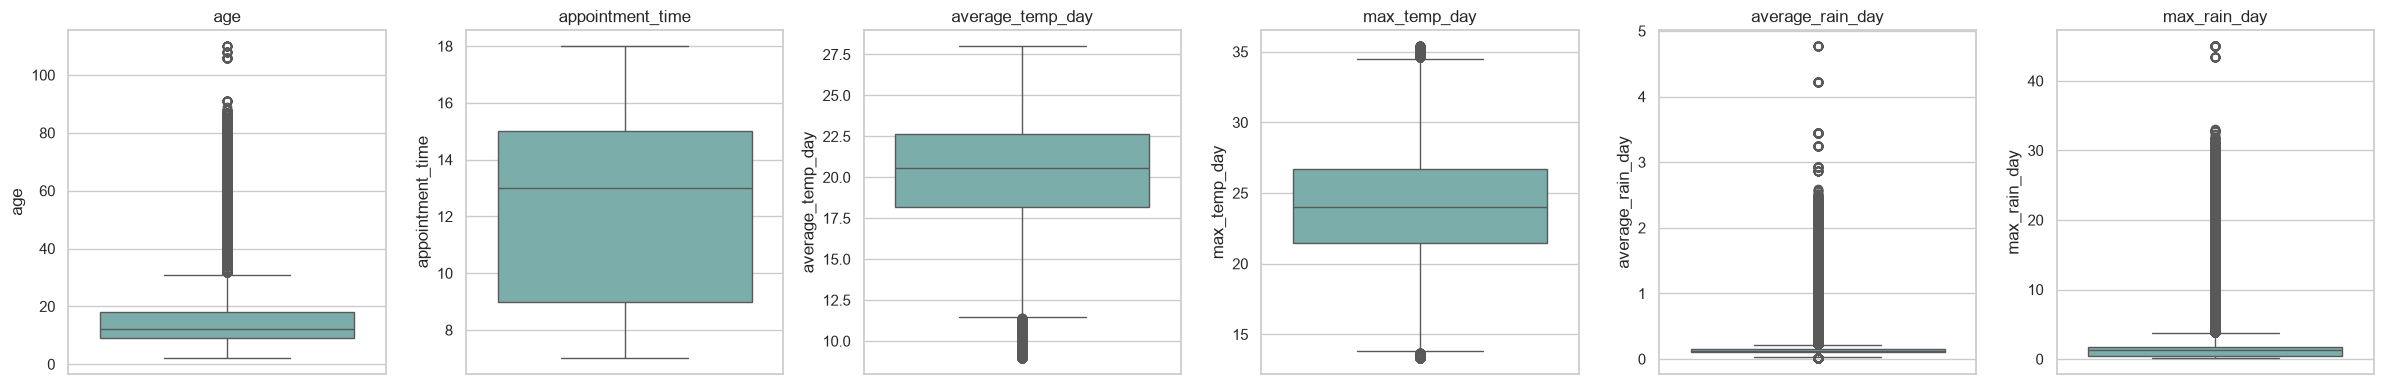

In [10]:
# IQR outlier detection for continuous numeric fields.
outlier_columns = [column for column in ['age', 'appointment_time', 'avg_temp', 'average_temp_day', 'max_temp', 'max_temp_day', 'avg_rain', 'average_rain_day', 'max_rain', 'max_rain_day'] if column in df.columns]
outlier_summary = []
for column in outlier_columns:
    values = pd.to_numeric(df[column], errors='coerce').dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_count = int(((values < lower_bound) | (values > upper_bound)).sum())
    outlier_summary.append({'feature': column, 'lower_bound': lower_bound, 'upper_bound': upper_bound, 'outlier_count': outlier_count, 'outlier_pct': outlier_count / len(values) * 100})

outlier_summary = pd.DataFrame(outlier_summary).sort_values('outlier_count', ascending=False)
display(outlier_summary.round(2))

fig, axes = plt.subplots(1, len(outlier_columns), figsize=(4 * len(outlier_columns), 4))
axes = [axes] if len(outlier_columns) == 1 else axes
for ax, column in zip(axes, outlier_columns):
    sns.boxplot(y=df[column], ax=ax, color='#72B7B2')
    ax.set_title(column)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()


## Interpretation note\n\nThe charts are descriptive, not causal. Preserve missingness in later modeling and ensure all predictor values are known before the appointment.\n